# Descriptive economics I: pandas basics

**Lecture 9 · Wednesday, 11 November 2026 · Notebook 1 of 1**

Economic data mostly come as **tables**: one row per observation, one column per variable. `pandas` is Python's standard tool for such tables. We work with one real dataset throughout: the **employment rate in Danish municipalities, 2008–2023**, from Statistics Denmark. It shows how the financial crisis hit local labour markets, and how they recovered.

You will use the same data again in Lecture 10 and in the data project.

## How to work

| Recording | Sections |
| --- | --- |
| Video 9A: DataFrames: load, look, select | 1–2 |
| Video 9B: New variables and changing data | 3–4 |
| Video 9C: Cleaning a messy Excel download | 5–6 |

**Before class (Tuesday, 23:59):** after the videos, solve warm-ups **W1–W2** in `Exercises.ipynb`, enter your answers in the Absalon quiz and upload the notebook with your code. Class is on Wednesday 18 November, together with Lecture 10.

**Reuse from Lectures 1–8:** lists, dictionaries, Boolean masks, NumPy arrays and plotting. **New:** `pandas` DataFrames.

**Table of contents**<a id='toc0_'></a>
- 1. [A DataFrame is a table](#toc1_)
- 2. [Load real data and select from it](#toc2_)
- 3. [New variables](#toc3_)
- 4. [Change, rename, drop and missing values](#toc4_)
- 5. [Cleaning a messy Excel download](#toc5_)
- 6. [Wide and long data](#toc6_)
- 7. [Summary](#toc7_)

<a id='video-9a'></a>
> **Start Video 9A**  
> Question: which Danish municipalities have the highest employment rates?

## 1. <a id='toc1_'></a>[A DataFrame is a table](#toc0_)

A `DataFrame` has **named columns** (variables) and **rows** (observations). Each row has an **index**, starting at 0. We can build one from a dictionary: each key becomes a column name.

The numbers below are the 2023 employment and participation rates of four municipalities, in percent of the population aged 16–64.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
small = pd.DataFrame({
    'municipality': ['Copenhagen', 'Aarhus', 'Odense', 'Allerød'],
    'emp_rate': [76.8, 74.2, 72.8, 84.7],
    'part_rate': [79.2, 76.5, 75.2, 85.8],
})
small

,municipality,emp_rate,part_rate
0,Copenhagen,76.8,79.2
1,Aarhus,74.2,76.5
2,Odense,72.8,75.2
3,Allerød,84.7,85.8


One column is a `Series`. Its values are a NumPy array, so everything from Lecture 4 works on it.

In [3]:
print(type(small['emp_rate']))
print(small['emp_rate'].to_numpy())
print('Mean employment rate:', small['emp_rate'].mean())

<class 'pandas.Series'>
[76.8 74.2 72.8 84.7]
Mean employment rate: 77.125


## 2. <a id='toc2_'></a>[Load real data and select from it](#toc0_)

`pd.read_csv` reads a comma-separated file into a DataFrame. Always look at new data before using it: `.head()` shows the first rows, `.shape` the number of rows and columns, `.info()` the column types, and `.describe()` summary statistics.

In [4]:
df = pd.read_csv('data/RAS200.csv')
print('Shape:', df.shape)
df.head()

Shape: (1584, 4)


,municipality,year,emp_rate,part_rate
0,Aabenraa,2008,74.6,76.3
1,Aabenraa,2009,71.6,75.2
2,Aabenraa,2010,70.9,74.5
3,Aabenraa,2011,70.2,74.0
4,Aabenraa,2012,69.5,73.7


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1584 entries, 0 to 1583
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   municipality  1584 non-null   str    
 1   year          1584 non-null   int64  
 2   emp_rate      1584 non-null   float64
 3   part_rate     1584 non-null   float64
dtypes: float64(2), int64(1), str(1)
memory usage: 49.6 KB


In [6]:
df.describe()

,year,emp_rate,part_rate
count,1584.000000,1584.000000,1584.000000
mean,2015.500000,74.622285,77.366477
std,4.611228,4.080628,3.474325
min,2008.000000,60.700000,65.500000
25%,2011.750000,71.900000,75.100000
50%,2015.500000,74.800000,77.500000
75%,2019.250000,77.600000,79.800000
max,2023.000000,84.900000,87.200000


The data are **long**: one row per municipality **and** year. `.unique()` lists the different values in a column.

**Pause and predict:** 1,584 rows and 16 years: how many municipalities?

In [7]:
print('Years:', df['year'].unique())
print('Number of municipalities:', len(df['municipality'].unique()))

Years: [2008 2009 2010 2011 2012 2013 2014 2015 2016 2017 2018 2019 2020 2021
 2022 2023]
Number of municipalities: 99


### Selecting rows and columns

- `df['col']` gives one column; `df[['col1', 'col2']]` gives several.
- `df.loc[rows, columns]` selects by **condition** and **name**. The rows are a Boolean mask, exactly as with NumPy arrays.
- `df.iloc[rows, columns]` selects by **position**, like NumPy indexing.

Combine conditions with `&` (and) or `|` (or), and put each condition in parentheses.

In [8]:
# a. all municipalities in 2023, two columns
I = df['year'] == 2023
df.loc[I, ['municipality', 'emp_rate']].head()

,municipality,emp_rate
15,Aabenraa,75.3
31,Aalborg,75.5
47,Aarhus,74.2
63,Albertslund,75.1
79,Allerød,84.7


In [9]:
# b. 2023 and an employment rate above 82 percent
I = (df['year'] == 2023) & (df['emp_rate'] > 82)
df.loc[I, ['municipality', 'emp_rate']]

,municipality,emp_rate
79,Allerød,84.7
223,Dragør,83.3
239,Egedal,84.4
303,Favrskov,82.3
415,Furesø,82.7
879,Lejre,82.1
1135,Rebild,82.5
1263,Skanderborg,82.5
1311,Solrød,84.4
1471,Vallensbæk,82.5


In [10]:
# c. by position: first three rows, first two columns
df.iloc[:3, :2]

,municipality,year
0,Aabenraa,2008
1,Aabenraa,2009
2,Aabenraa,2010


`sort_values` orders the rows. The highest and lowest employment rates in 2023:

In [11]:
df_2023 = df.loc[df['year'] == 2023]
df_2023 = df_2023.sort_values('emp_rate', ascending=False)

print('Highest:')
print(df_2023[['municipality', 'emp_rate']].head(3))
print('Lowest:')
print(df_2023[['municipality', 'emp_rate']].tail(3))

Highest:
     municipality  emp_rate
79        Allerød      84.7
239        Egedal      84.4
1311       Solrød      84.4
Lowest:
     municipality  emp_rate
1087       Odense      72.8
863     Langeland      71.5
911       Lolland      68.3


The highest rates are in suburbs north and south of Copenhagen; the lowest on the islands of Lolland and Langeland.

> **Stop Video 9A.** You can load a table, look at it and select rows and columns.

<a id='video-9b'></a>
> **Start Video 9B**  
> Question: how did the financial crisis show up in local labour markets?

## 3. <a id='toc3_'></a>[New variables](#toc0_)

A new column is created with `df['new'] = ...`. The right-hand side is usually a calculation with other columns, done row by row.

The participation rate counts everybody in the labour force; the employment rate only those with a job. The difference is the share of the population aged 16–64 who are **unemployed**, in percent.

In [12]:
df['unemp_share'] = df['part_rate'] - df['emp_rate']
df.head()

,municipality,year,emp_rate,part_rate,unemp_share
0,Aabenraa,2008,74.6,76.3,1.7
1,Aabenraa,2009,71.6,75.2,3.6
2,Aabenraa,2010,70.9,74.5,3.6
3,Aabenraa,2011,70.2,74.0,3.8
4,Aabenraa,2012,69.5,73.7,4.2


**Pause and predict:** how did the average unemployed share change from 2008 to 2009?

In [13]:
for year in [2008, 2009, 2010, 2023]:
    I = df['year'] == year
    print(f'{year}: average unemployed share = {df.loc[I, "unemp_share"].mean():.2f} percent')

2008: average unemployed share = 1.70 percent
2009: average unemployed share = 3.58 percent
2010: average unemployed share = 3.66 percent
2023: average unemployed share = 1.85 percent


The share roughly **doubled** in the financial crisis and was back near its 2008 level by 2023. (In Lecture 10, `groupby` does this for all years in one line.)

A constant also works on the right-hand side; it is copied to every row:

In [14]:
df['country'] = 'Denmark'
df.head(3)

,municipality,year,emp_rate,part_rate,unemp_share,country
0,Aabenraa,2008,74.6,76.3,1.7,Denmark
1,Aabenraa,2009,71.6,75.2,3.6,Denmark
2,Aabenraa,2010,70.9,74.5,3.6,Denmark


## 4. <a id='toc4_'></a>[Change, rename, drop and missing values](#toc0_)

### Changing a subset of rows

To change some rows, **select and assign in one step** with `.loc`:

In [15]:
df['crisis'] = False
df.loc[df['year'].isin([2009, 2010]), 'crisis'] = True      # .isin: True if the year is 2009 or 2010
df.loc[df['year'].isin([2008, 2009, 2010, 2011]), ['municipality', 'year', 'crisis']].head(4)

,municipality,year,crisis
0,Aabenraa,2008,False
1,Aabenraa,2009,True
2,Aabenraa,2010,True
3,Aabenraa,2011,False


**A common mistake:** selecting first and changing afterwards changes only a **copy**, not `df`:

In [16]:
subset = df.loc[df['year'] == 2023]
subset['emp_rate'] = 0.0                           # changes subset only (pandas 2 may warn: SettingWithCopyWarning)
print('Any zero employment rates in df?', (df['emp_rate'] == 0.0).any())

Any zero employment rates in df? False


### Rename, drop and sort

`rename` takes a dictionary from old to new names. `drop` removes columns (or rows). Both return a **new** DataFrame, so assign the result.

In [17]:
df = df.rename(columns={'emp_rate': 'employment_rate'})
df = df.drop(columns=['country'])
df.head(3)

,municipality,year,employment_rate,part_rate,unemp_share,crisis
0,Aabenraa,2008,74.6,76.3,1.7,False
1,Aabenraa,2009,71.6,75.2,3.6,True
2,Aabenraa,2010,70.9,74.5,3.6,True


### Missing values

Real data have gaps. `pandas` marks a missing value as `NaN` ("not a number"). Suppose one value was not reported:

In [18]:
gaps = small.copy()
gaps.loc[2, 'emp_rate'] = np.nan
print(gaps)
print('Missing values per column:')
print(gaps.isna().sum())
print('Mean ignores NaN:', gaps['emp_rate'].mean())
print('Rows without gaps:', gaps.dropna().shape[0])

  municipality  emp_rate  part_rate
0   Copenhagen      76.8       79.2
1       Aarhus      74.2       76.5
2       Odense       NaN       75.2
3      Allerød      84.7       85.8
Missing values per column:
municipality    0
emp_rate        1
part_rate       0
dtype: int64
Mean ignores NaN: 78.56666666666666
Rows without gaps: 3


**Always count missing values before you compute averages.** `pandas` skips them silently, which is convenient but can hide a problem.

> **Stop Video 9B.** You can create variables, change selected rows, rename, drop and handle missing values.

<a id='video-9c'></a>
> **Start Video 9C**  
> Question: how do we get from a messy download to the clean file we used above?

## 5. <a id='toc5_'></a>[Cleaning a messy Excel download](#toc0_)

The file `RAS200.csv` did not come clean from Statistics Denmark. The download looks like `data/raw/RAS200_only_employment_rate.xlsx`. `pd.read_excel` reads it; first we just look.

In [19]:
filename = 'data/raw/RAS200_only_employment_rate.xlsx'
pd.read_excel(filename).iloc[:6, :7]

,"Activity and employment rates (end November) by frequency, sex, age, ancestry, region and time",Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6
0,Units: Per cent,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,2008.0,2009.0
2,Employment rate,Total,16-64 years,Total,All Denmark,76.0,72.8
3,NaN,NaN,NaN,NaN,Region Hovedstaden,75.8,73.3
4,NaN,NaN,NaN,NaN,Province Byen København,73.4,71.0
5,NaN,NaN,NaN,NaN,Copenhagen,72.5,70.0


Three problems: a title and units in the first rows, empty columns on the left, and years as column names. We fix them one at a time.

**Step 1: skip the title rows.**

In [20]:
raw = pd.read_excel(filename, skiprows=2)
raw.iloc[:4, :7]

,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,2008,2009
0,Employment rate,Total,16-64 years,Total,All Denmark,76.0,72.8
1,NaN,NaN,NaN,NaN,Region Hovedstaden,75.8,73.3
2,NaN,NaN,NaN,NaN,Province Byen København,73.4,71.0
3,NaN,NaN,NaN,NaN,Copenhagen,72.5,70.0


**Step 2: drop the empty columns and rename the municipality column.**

In [21]:
raw = raw.drop(columns=['Unnamed: 0', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3'])
raw = raw.rename(columns={'Unnamed: 4': 'municipality'})
raw.iloc[:6, :5]

,municipality,2008,2009,2010,2011
0,All Denmark,76.0,72.8,72.1,71.8
1,Region Hovedstaden,75.8,73.3,72.6,72.5
2,Province Byen København,73.4,71.0,70.5,70.5
3,Copenhagen,72.5,70.0,69.7,69.6
4,Frederiksberg,75.6,73.7,72.7,72.8
5,Dragør,80.5,78.8,78.5,78.5


**Step 3: drop rows that are not municipalities.** The file also contains Denmark as a whole, regions and provinces. The string method `.str.contains` finds them.

**Pause and predict:** 116 rows before; how many municipalities remain?

In [22]:
I = raw['municipality'].str.contains('Region')
I = I | raw['municipality'].str.contains('Province')
I = I | (raw['municipality'] == 'All Denmark')
print('Rows to drop:', I.sum())

wide = raw.loc[~I]
print('Municipalities left:', wide.shape[0])
wide.iloc[:3, :5]

Rows to drop: 17
Municipalities left: 99


,municipality,2008,2009,2010,2011
3,Copenhagen,72.5,70.0,69.7,69.6
4,Frederiksberg,75.6,73.7,72.7,72.8
5,Dragør,80.5,78.8,78.5,78.5


`~I` means "not I": keep every row that is not a region, a province or Denmark.

This **wide** table already answers questions across years. Which municipalities saw the largest fall in the employment rate from 2008 to 2009?

In [23]:
wide = wide.copy()
wide['change_08_09'] = wide['2009'] - wide['2008']
wide.sort_values('change_08_09')[['municipality', '2008', '2009', 'change_08_09']].head(3)

,municipality,2008,2009,change_08_09
109,Læsø,73.1,67.0,-6.1
84,Hedensted,82.3,77.4,-4.9
75,Sønderborg,75.1,70.3,-4.8


## 6. <a id='toc6_'></a>[Wide and long data](#toc0_)

The same data can be stored in two shapes:

| Wide: one row per municipality | Long: one row per municipality and year |
| --- | --- |
| columns `municipality, 2008, 2009, …, 2023` | columns `municipality, year, emp_rate` |
| easy to compare two years | easy to select, plot and combine |

Most analysis in `pandas` is easier in **long** form. `melt` turns wide into long: `id_vars` stays as it is, all other columns are stacked.

In [24]:
long = wide.drop(columns=['change_08_09']).melt(id_vars='municipality', var_name='year', value_name='emp_rate')
long['year'] = long['year'].astype(int)          # the year was a column name, i.e. text
print('Shape:', long.shape)
long.head()

Shape: (1584, 3)


,municipality,year,emp_rate
0,Copenhagen,2008,72.5
1,Frederiksberg,2008,75.6
2,Dragør,2008,80.5
3,Tårnby,2008,79.0
4,Albertslund,2008,73.1


`pivot_table` goes the other way, from long back to wide:

In [25]:
back = long.pivot_table(index='municipality', columns='year', values='emp_rate')
back.iloc[:3, :4]

year,2008,2009,2010,2011
municipality,,,,
Aabenraa,74.6,71.6,70.9,70.2
Aalborg,73.2,70.1,69.7,69.2
Aarhus,72.6,69.8,69.0,68.0


### A known answer as a test

Our cleaned data should be exactly the employment rates in `RAS200.csv`. We sort both tables the same way and compare:

In [26]:
clean = long.sort_values(['municipality', 'year']).reset_index(drop=True)
reference = pd.read_csv('data/RAS200.csv').sort_values(['municipality', 'year']).reset_index(drop=True)

print('Same rows:', (clean['municipality'] == reference['municipality']).all() and (clean['year'] == reference['year']).all())
print('Same values:', np.allclose(clean['emp_rate'], reference['emp_rate']))

Same rows: True
Same values: True


### Plot and save

Long data make plots easy: select one municipality and plot its rate over time.

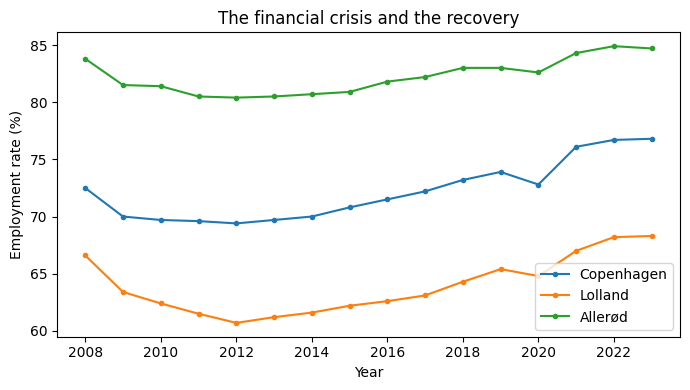

In [27]:
fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(1, 1, 1)
for name in ['Copenhagen', 'Lolland', 'Allerød']:
    I = clean['municipality'] == name
    ax.plot(clean.loc[I, 'year'], clean.loc[I, 'emp_rate'], marker='.', label=name)
ax.set_xlabel('Year')
ax.set_ylabel('Employment rate (%)')
ax.set_title('The financial crisis and the recovery')
ax.legend()
fig.tight_layout()
plt.show()

Finally, save the clean data, so the cleaning runs only once. `index=False` leaves out the row numbers.

In [28]:
clean.to_csv('data/emp_rate_clean.csv', index=False)

## 7. <a id='toc7_'></a>[Summary](#toc0_)

| Task | Code |
| --- | --- |
| load | `pd.read_csv(...)`, `pd.read_excel(..., skiprows=...)` |
| look | `.head()`, `.shape`, `.info()`, `.describe()`, `.unique()` |
| select | `df.loc[mask, ['col']]`, `df.iloc[rows, cols]`, `sort_values` |
| create and change | `df['new'] = ...`, `df.loc[mask, 'col'] = value` (one step) |
| tidy | `rename`, `drop`, `isna`, `dropna`, `.str.contains` |
| reshape | `melt` (wide → long), `pivot_table` (long → wide) |
| save | `df.to_csv(..., index=False)` |

**Workflow for every new dataset:** look → clean → check against something you know → save.

> **Stop Video 9C.** End of Lecture 9's recording sequence. In Lecture 10 we download data directly with an API, compute statistics per municipality with `groupby`, and combine datasets with `merge`.

### References

[pandas getting started](https://pandas.pydata.org/docs/getting_started/index.html) and [Statistics Denmark, table RAS200](https://www.statbank.dk/RAS200). The newer package [polars](https://pola.rs/) is an alternative to pandas; we stick to pandas.